# TP 2 — Arbre de décision : météo et champignons
**Module** : Machine Learning · Algorithmes  |  **Durée** : 3 h  |  **Travail** : en binôme
**Étudiants** : *(noms du binôme)*  |  **Date** : *(à remplir)*

---
##  Contexte et objectif du TP
Un **arbre de décision** est un modèle de classification qui pose une suite de questions simples
(« le ciel est-il ensoleillé ? », « l'odeur est-elle fétide ? ») pour arriver à une décision.
Chaque question coupe les données en deux ou plusieurs groupes de plus en plus **purs**
(c'est-à-dire contenant presque une seule classe).

Ce TP a pour but de comprendre **comment** l'arbre choisit ses questions, puis de l'appliquer à un vrai problème :
**reconnaître un champignon toxique**. Nous allons :

| Partie | Ce que l'on fait | Notion clé | Points |
|---|---|---|---|
| **A** | Construire un arbre **à la main** sur le petit jeu météo (14 journées) | Gini, entropie, gain | 7 |
| **B** | Construire un arbre avec **Python / scikit-learn** sur 8 124 champignons | Entraînement, test, surapprentissage | 9 |
| **C** | Refaire l'expérience avec **Orange** (outil visuel) | Validation croisée, CA, AUC | 4 |

## Rappel des formules (de l'énoncé)
* **Gini** = 1 − Σ pₖ²  → 0 pour un nœud pur, 0,5 au maximum avec deux classes
* **Entropie** = − Σ pₖ log₂ pₖ  → 0 pour un nœud pur, 1 bit au maximum avec deux classes
* **Gain** = impureté du parent − Σ (nᵥ / n) × impureté de l'enfant v  → on choisit la question au **plus grand gain**

##  Livrables
1. Ce notebook exécuté (`.ipynb`) · 2. le fichier Orange (`.ows`) · 3. l'arbre de la partie A dessiné à la main.

##  Mini-glossaire : les étapes d'un projet de Machine Learning
Dans chaque partie nous suivrons toujours la même démarche. Voici ce que signifie chaque mot :

| Étape | Signification | Pourquoi on la fait |
|---|---|---|
| **Importation** | Charger les bibliothèques (pandas, scikit-learn…) puis les données dans la mémoire | Sans données ni outils, rien n'est possible |
| **Exploration / Visualisation** | Regarder les données : tailles, valeurs, proportions, graphiques | Comprendre le problème et repérer les anomalies avant de modéliser |
| **Prétraitement (encodage)** | Transformer le texte en nombres (*one-hot*) | scikit-learn ne sait calculer qu'avec des nombres |
| **Séparation (train/test)** | Couper les données en un jeu d'**entraînement** (70 %) et un jeu de **test** (30 %) | Évaluer le modèle sur des exemples qu'il n'a **jamais vus**, sinon la note est truquée |
| **Entraînement (fit)** | Le modèle apprend les questions à poser à partir du jeu d'entraînement | C'est l'apprentissage proprement dit |
| **Prédiction** | Le modèle donne sa réponse sur de nouveaux exemples | Voir ce qu'il fait « en vrai » |
| **Test / Évaluation** | Comparer les prédictions aux vraies réponses (accuracy, matrice de confusion) | Mesurer la qualité, y compris le **type** d'erreurs |
| **Résultat / Interprétation** | Lire les règles, les importances, conclure | Un modèle n'a de valeur que si on sait l'expliquer |

## 0. Importation des bibliothèques et des fichiers

**Importation** : on charge les outils dont on a besoin.
* `pandas` : manipuler des tableaux de données (DataFrame) ;
* `numpy` : calcul numérique (ici les logarithmes de l'entropie) ;
* `matplotlib` : dessiner des graphiques ;
* `scikit-learn` : l'arbre de décision, la découpe train/test et les métriques.

*Pourquoi ?* Python seul ne connaît pas ces outils : il faut les importer une fois en début de notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

pd.set_option("display.max_columns", 30)   # afficher toutes les colonnes des tableaux
print("Bibliothèques importées ✅")

Bibliothèques importées ✅


**Importation des fichiers** : sur Google Colab, les fichiers de votre ordinateur ne sont pas visibles directement.
La cellule suivante ouvre une fenêtre pour envoyer `meteo.csv` **et** `champignons.csv`.
(En Jupyter local, placez simplement les deux fichiers dans le même dossier que le notebook.)

---
# PARTIE A — L'arbre à la main (jeu météo)  · *7 points*
**But** : comprendre le mécanisme de l'arbre sur un exemple assez petit (14 lignes) pour tout vérifier à la main.
Python ne sert ici que de **calculatrice** pour contrôler nos calculs papier.

La question à laquelle on répond : *« Doit-on jouer dehors, selon le ciel, la température, l'humidité et le vent ? »*

## A.1 — Mélange initial
### Importation et exploration (visualisation) des données
*Pourquoi ?* Avant tout calcul, on doit connaître les colonnes, leurs valeurs et le nombre de Oui / Non.

In [5]:
df = pd.read_csv("meteo.csv")      # importation
print("Dimensions (lignes, colonnes) :", df.shape)
display(df)                        # on regarde les 14 journées
print("Colonnes :", list(df.columns))

Dimensions (lignes, colonnes) : (14, 5)


,Ciel,Température,Humidité,Vent,Jouer
0,Soleil,Chaude,Élevée,Faible,Non
1,Soleil,Chaude,Élevée,Fort,Non
2,Couvert,Chaude,Élevée,Faible,Oui
3,Pluie,Douce,Élevée,Faible,Oui
4,Pluie,Fraîche,Normale,Faible,Oui
5,Pluie,Fraîche,Normale,Fort,Non
6,Couvert,Fraîche,Normale,Fort,Oui
7,Soleil,Douce,Élevée,Faible,Non
8,Soleil,Fraîche,Normale,Faible,Oui
9,Pluie,Douce,Normale,Faible,Oui


Colonnes : ['Ciel', 'Température', 'Humidité', 'Vent', 'Jouer']


Effectifs de la cible :
 Jouer
Oui    9
Non    5
Name: count, dtype: int64


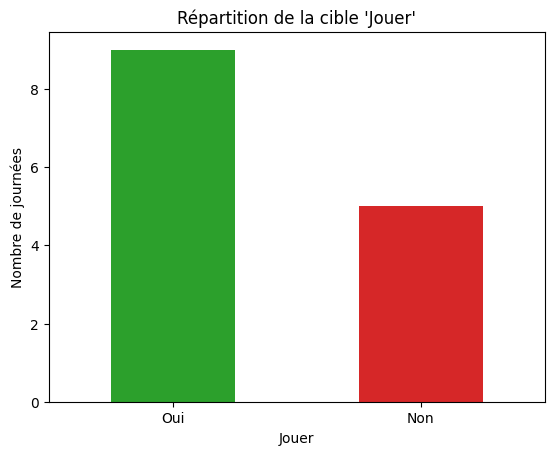

In [6]:
#  Adapter si la colonne cible ne s'appelle pas exactement "Jouer"
CIBLE = "Jouer"

effectifs = df[CIBLE].value_counts()
print("Effectifs de la cible :\n", effectifs)

# Visualisation de la répartition
effectifs.plot(kind="bar", color=["tab:green", "tab:red"], rot=0)
plt.title("Répartition de la cible 'Jouer'")
plt.ylabel("Nombre de journées")
plt.show()

### Définition des mesures d'impureté
Une **impureté** mesure à quel point un groupe est *mélangé*. Un groupe 100 % « Oui » est pur (impureté 0) ;
un groupe moitié Oui / moitié Non est le plus mélangé possible.
*Pourquoi ?* L'arbre veut choisir des questions qui produisent des groupes les plus purs possible.

In [7]:
def gini(serie):
    """Gini = 1 - somme(pk^2) : 0 si le noeud est pur, 0.5 max avec deux classes."""
    p = serie.value_counts(normalize=True)      # proportions pk de chaque classe
    return 1 - (p ** 2).sum()

def entropie(serie):
    """Entropie = -somme(pk * log2(pk)) : 0 si pur, 1 bit max avec deux classes."""
    p = serie.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

### Calcul pour la racine (tout le jeu de données)
La **racine** est le nœud de départ : il contient toutes les journées. Son impureté est la référence
par rapport à laquelle on mesurera le gain de chaque question.

In [ ]:
n = len(df)
print(f"Racine : {n} journées -> {effectifs.to_dict()}")
print(f"Gini racine     = {gini(df[CIBLE]):.4f}")
print(f"Entropie racine = {entropie(df[CIBLE]):.4f}")

# Détail du calcul "à la main" avec VOS effectifs (à recopier dans le rapport)
p = (effectifs / n)
print("\nDétail Gini     : 1 - (" + " + ".join(f"({c}/{n})²" for c in effectifs) + ")")
print("Détail Entropie : -(" + " + ".join(f"({c}/{n})·log2({c}/{n})" for c in effectifs) + ")")

## A.2 — Gain de chaque variable
Pour **chaque variable** (Ciel, Température, Humidité, Vent), on simule la question « quelle est sa valeur ? » :
1. on découpe les 14 journées en groupes (un par valeur) ;
2. on calcule le Gini de **chaque groupe** ;
3. on fait la moyenne pondérée par la taille des groupes (**Gini pondéré**) ;
4. **Gain** = Gini du parent − Gini pondéré.

*Pourquoi ?* Plus le gain est grand, plus la question « nettoie » les données. La variable au gain maximal devient la **racine**.
La fonction demandée par l'énoncé s'appelle `gain_gini(df, variable)`.

In [8]:
def gain_gini(df, variable, cible=CIBLE, detail=True):
    """Gain = Gini(parent) - somme( n_v / n * Gini(enfant v) )"""
    n = len(df)
    gini_parent = gini(df[cible])
    gini_pondere = 0
    for valeur, groupe in df.groupby(variable):
        g = gini(groupe[cible])
        poids = len(groupe) / n
        gini_pondere += poids * g
        if detail:
            print(f"   {variable} = {str(valeur):<10} n={len(groupe):2d}  "
                  f"{groupe[cible].value_counts().to_dict()}  Gini={g:.4f}")
    gain = gini_parent - gini_pondere
    if detail:
        print(f"   -> Gini pondéré = {gini_pondere:.4f}   |   Gain = {gain:.4f}\n")
    return gain

def gain_entropie(df, variable, cible=CIBLE):
    """Même principe avec l'entropie (gain d'information), pour comparer."""
    n = len(df)
    pondere = sum(len(g) / n * entropie(g[cible]) for _, g in df.groupby(variable))
    return entropie(df[cible]) - pondere

=== Question sur : Ciel ===
   Ciel = Couvert    n= 4  {'Oui': 4}  Gini=0.0000
   Ciel = Pluie      n= 5  {'Oui': 3, 'Non': 2}  Gini=0.4800
   Ciel = Soleil     n= 5  {'Non': 3, 'Oui': 2}  Gini=0.4800
   -> Gini pondéré = 0.3429   |   Gain = 0.1163

=== Question sur : Température ===
   Température = Chaude     n= 4  {'Non': 2, 'Oui': 2}  Gini=0.5000
   Température = Douce      n= 6  {'Oui': 4, 'Non': 2}  Gini=0.4444
   Température = Fraîche    n= 4  {'Oui': 3, 'Non': 1}  Gini=0.3750
   -> Gini pondéré = 0.4405   |   Gain = 0.0187

=== Question sur : Humidité ===
   Humidité = Normale    n= 7  {'Oui': 6, 'Non': 1}  Gini=0.2449
   Humidité = Élevée     n= 7  {'Non': 4, 'Oui': 3}  Gini=0.4898
   -> Gini pondéré = 0.3673   |   Gain = 0.0918

=== Question sur : Vent ===
   Vent = Faible     n= 8  {'Oui': 6, 'Non': 2}  Gini=0.3750
   Vent = Fort       n= 6  {'Non': 3, 'Oui': 3}  Gini=0.5000
   -> Gini pondéré = 0.4286   |   Gain = 0.0306

Gains (Gini)     : {'Ciel': np.float64(0.1163), 'Tem

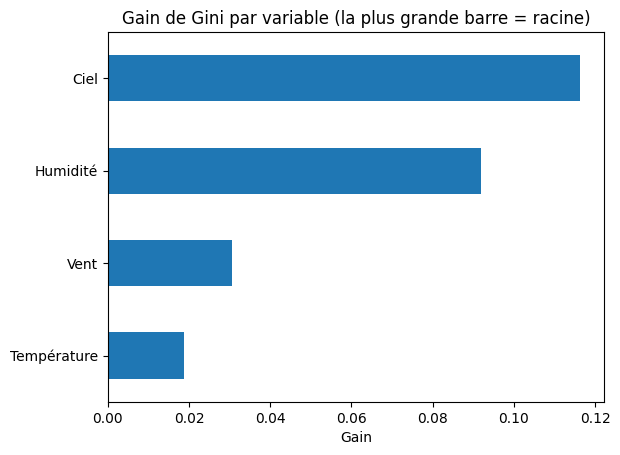

In [9]:
variables = [c for c in df.columns if c != CIBLE]

gains = {}
for v in variables:
    print(f"=== Question sur : {v} ===")
    gains[v] = gain_gini(df, v)

print("Gains (Gini)     :", {k: round(val, 4) for k, val in gains.items()})
print("Gains (entropie) :", {v: round(gain_entropie(df, v), 4) for v in variables})

racine = max(gains, key=gains.get)
print(f"\n✅ La variable choisie comme RACINE est : {racine}")

# Visualisation des gains
pd.Series(gains).sort_values().plot(kind="barh", color="tab:blue")
plt.title("Gain de Gini par variable (la plus grande barre = racine)")
plt.xlabel("Gain")
plt.show()

✍️ **Ma réponse A.2** : *(recopier le tableau : Gini de chaque groupe, Gini pondéré, gain, pour les 4 variables. Conclure : la racine est … car son gain est le plus grand.)*

## A.3 — Terminer l'arbre
On **répète le même raisonnement** dans chaque branche de la racine : on ne garde que les journées de la branche,
on recalcule les gains des variables restantes, on choisit la meilleure, etc., jusqu'à obtenir des **feuilles pures**
(un nœud qui ne contient plus qu'une seule classe : on peut alors répondre).

*Pourquoi ?* C'est exactement l'algorithme d'un arbre de décision : choisir la meilleure question, couper, recommencer (récursivité).

**Étape 1 — Gains dans chaque branche de la racine** (à détailler sur papier pour les branches non pures) :

In [10]:
for valeur, sous in df.groupby(racine):
    print("=" * 60)
    print(f"Branche {racine} = {valeur}   ->   {sous[CIBLE].value_counts().to_dict()}   (Gini = {gini(sous[CIBLE]):.4f})")
    if sous[CIBLE].nunique() == 1:
        print("   Noeud pur : c'est une feuille, rien à découper.")
        continue
    for v in [c for c in variables if c != racine]:
        print(f"--- question sur {v} ---")
        gain_gini(sous, v)

Branche Ciel = Couvert   ->   {'Oui': 4}   (Gini = 0.0000)
   Noeud pur : c'est une feuille, rien à découper.
Branche Ciel = Pluie   ->   {'Oui': 3, 'Non': 2}   (Gini = 0.4800)
--- question sur Température ---
   Température = Douce      n= 3  {'Oui': 2, 'Non': 1}  Gini=0.4444
   Température = Fraîche    n= 2  {'Oui': 1, 'Non': 1}  Gini=0.5000
   -> Gini pondéré = 0.4667   |   Gain = 0.0133

--- question sur Humidité ---
   Humidité = Normale    n= 3  {'Oui': 2, 'Non': 1}  Gini=0.4444
   Humidité = Élevée     n= 2  {'Oui': 1, 'Non': 1}  Gini=0.5000
   -> Gini pondéré = 0.4667   |   Gain = 0.0133

--- question sur Vent ---
   Vent = Faible     n= 3  {'Oui': 3}  Gini=0.0000
   Vent = Fort       n= 2  {'Non': 2}  Gini=0.0000
   -> Gini pondéré = 0.0000   |   Gain = 0.4800

Branche Ciel = Soleil   ->   {'Non': 3, 'Oui': 2}   (Gini = 0.4800)
--- question sur Température ---
   Température = Chaude     n= 2  {'Non': 2}  Gini=0.0000
   Température = Douce      n= 2  {'Non': 1, 'Oui': 1}  Gini

**Étape 2 — Construction automatique de tout l'arbre et affichage des règles SI… ALORS :**

In [11]:
def construire_arbre(data, variables_dispo, indent=""):
    """Construit l'arbre (choix par gain de Gini) et affiche les règles."""
    classes = data[CIBLE].value_counts()

    # Cas d'arrêt : noeud pur, ou plus aucune variable disponible -> feuille
    if len(classes) == 1 or not variables_dispo:
        print(f"{indent}ALORS {CIBLE} = {classes.idxmax()}   {classes.to_dict()}")
        return

    gains_loc = {v: gain_gini(data, v, detail=False) for v in variables_dispo}
    meilleure = max(gains_loc, key=gains_loc.get)
    print(f"{indent}[Question : {meilleure} ?]  (gain = {gains_loc[meilleure]:.3f})  {classes.to_dict()}")

    reste = [v for v in variables_dispo if v != meilleure]
    for valeur, sous in data.groupby(meilleure):
        print(f"{indent}  SI {meilleure} = {valeur}")
        construire_arbre(sous, reste, indent + "        ")

construire_arbre(df, variables)

[Question : Ciel ?]  (gain = 0.116)  {'Oui': 9, 'Non': 5}
  SI Ciel = Couvert
        ALORS Jouer = Oui   {'Oui': 4}
  SI Ciel = Pluie
        [Question : Vent ?]  (gain = 0.480)  {'Oui': 3, 'Non': 2}
          SI Vent = Faible
                ALORS Jouer = Oui   {'Oui': 3}
          SI Vent = Fort
                ALORS Jouer = Non   {'Non': 2}
  SI Ciel = Soleil
        [Question : Humidité ?]  (gain = 0.480)  {'Non': 3, 'Oui': 2}
          SI Humidité = Normale
                ALORS Jouer = Oui   {'Oui': 2}
          SI Humidité = Élevée
                ALORS Jouer = Non   {'Non': 3}


✍️ **Ma réponse A.3** :
* **Arbre dessiné à la main** : *(à joindre en photo/scan — livrable n°3)*
* **Règles SI… ALORS** : *(recopier celles affichées ci-dessus, par exemple « SI Ciel = Couvert ALORS Jouer = Oui »)*

### Vérification avec scikit-learn
Pour contrôler que notre arbre manuel est cohérent, on entraîne un arbre scikit-learn sur les mêmes 14 lignes.
(Les variables texte sont d'abord transformées en nombres — voir la partie B pour l'explication de `get_dummies`.)

In [12]:
X_meteo = pd.get_dummies(df[variables], prefix_sep="=")
arbre_meteo = DecisionTreeClassifier(criterion="gini", random_state=0).fit(X_meteo, df[CIBLE])
print(export_text(arbre_meteo, feature_names=list(X_meteo.columns)))
# Remarque : scikit-learn fait des coupures binaires (variable = valeur ? oui/non),
# alors que notre arbre manuel crée une branche par valeur. La racine doit toutefois être cohérente.

|--- Ciel=Couvert <= 0.50
|   |--- Humidité=Élevée <= 0.50
|   |   |--- Vent=Fort <= 0.50
|   |   |   |--- class: Oui
|   |   |--- Vent=Fort >  0.50
|   |   |   |--- Ciel=Pluie <= 0.50
|   |   |   |   |--- class: Oui
|   |   |   |--- Ciel=Pluie >  0.50
|   |   |   |   |--- class: Non
|   |--- Humidité=Élevée >  0.50
|   |   |--- Ciel=Soleil <= 0.50
|   |   |   |--- Vent=Faible <= 0.50
|   |   |   |   |--- class: Non
|   |   |   |--- Vent=Faible >  0.50
|   |   |   |   |--- class: Oui
|   |   |--- Ciel=Soleil >  0.50
|   |   |   |--- class: Non
|--- Ciel=Couvert >  0.50
|   |--- class: Oui



---
# PARTIE B — Les champignons avec Python  · *9 points*
**But** : appliquer la même idée à un vrai problème. Le jeu **Mushroom** (UCI, 1987) décrit **8 124 champignons**
par 13 caractéristiques (odeur, couleur du chapeau, forme…) et indique s'ils sont **comestibles** ou **toxiques**.

Ici, la machine choisit les questions à notre place ; notre rôle est de **bien l'entraîner, la tester et l'interpréter**.

## B.1 — Découvrir
### Importation et exploration
*Pourquoi ?* Vérifier la taille du jeu, l'absence de valeurs manquantes, et surtout **l'équilibre des classes**
(si 99 % des champignons étaient comestibles, une accuracy de 99 % ne voudrait rien dire).

In [13]:
champ = pd.read_csv("champignons.csv")                 # importation
print("Dimensions :", champ.shape)
display(champ.head())                                  # aperçu des premières lignes
print("\nValeurs manquantes par colonne :\n", champ.isna().sum()[champ.isna().sum() > 0])
print("Types :\n", champ.dtypes.value_counts())

Dimensions : (8124, 14)


,classe,forme_chapeau,surface_chapeau,couleur_chapeau,meurtrissures,odeur,espacement_lamelles,taille_lamelles,couleur_lamelles,forme_pied,type_anneau,couleur_spores,population,habitat
0,toxique,convexe,lisse,brun,oui,piquante,serre,etroite,noir,evase,pendant,noir,dispersee,urbain
1,comestible,convexe,lisse,jaune,oui,amande,serre,large,noir,evase,pendant,brun,nombreuse,herbes
2,comestible,cloche,lisse,blanc,oui,anis,serre,large,brun,evase,pendant,brun,nombreuse,prairies
3,toxique,convexe,ecailleuse,blanc,oui,piquante,serre,etroite,brun,evase,pendant,noir,dispersee,urbain
4,comestible,convexe,lisse,gris,non,aucune,tres_serre,large,noir,effile,evanescent,brun,abondante,herbes



Valeurs manquantes par colonne :
 Series([], dtype: int64)
Types :
 object    14
Name: count, dtype: int64


In [14]:
# Valeurs de la cible : ⚠️ vérifier l'orthographe exacte !
classes = sorted(champ["classe"].unique())
print("Valeurs de 'classe' :", classes)

# On détecte automatiquement l'étiquette « toxique » (à corriger à la main si besoin)
candidats = ["toxique", "Toxique", "poisonous", "p", "P", "t"]
TOXIQUE = next((c for c in classes if str(c) in candidats), None)
print("Étiquette retenue pour 'toxique' :", TOXIQUE)
assert TOXIQUE is not None, "Écrire à la main : TOXIQUE = '...' (voir la liste ci-dessus)"

Valeurs de 'classe' : ['comestible', 'toxique']
Étiquette retenue pour 'toxique' : toxique


### Proportion de champignons toxiques (visualisation)

classe
comestible    4208
toxique       3916
Name: count, dtype: int64
classe
comestible    0.518
toxique       0.482
Name: proportion, dtype: float64


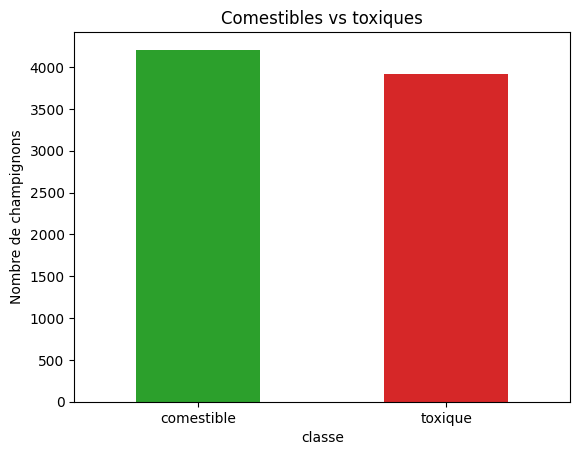

In [15]:
print(champ["classe"].value_counts())
print(champ["classe"].value_counts(normalize=True).round(4))

champ["classe"].value_counts().plot(kind="bar", color=["tab:green", "tab:red"], rot=0)
plt.title("Comestibles vs toxiques")
plt.ylabel("Nombre de champignons")
plt.show()

### Tableau croisé `odeur × classe`
Un **tableau croisé** compte, pour chaque odeur, combien de champignons sont comestibles ou toxiques.
*Pourquoi ?* Pour repérer à l'œil une variable très informative **avant** d'entraîner quoi que ce soit.

classe,comestible,toxique
odeur,,
amande,400,0
anis,400,0
aucune,3408,120
creosote,0,192
epicee,0,576
fetide,0,2160
moisi,0,36
piquante,0,256
poisson,0,576


classe,comestible,toxique
odeur,,
amande,1.000,0.000
anis,1.000,0.000
aucune,0.966,0.034
creosote,0.000,1.000
epicee,0.000,1.000
fetide,0.000,1.000
moisi,0.000,1.000
piquante,0.000,1.000
poisson,0.000,1.000


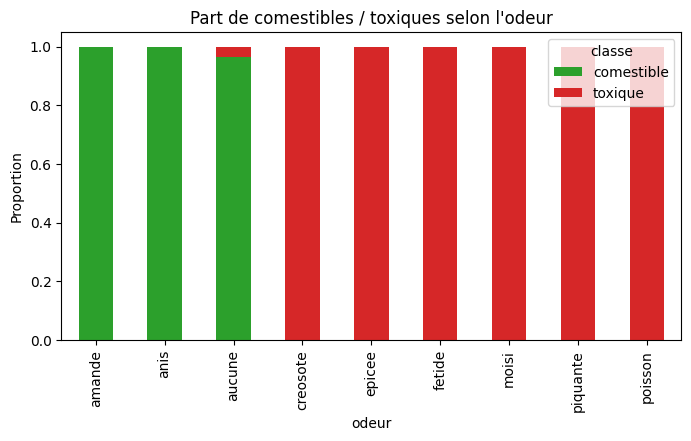

In [16]:
tab = pd.crosstab(champ["odeur"], champ["classe"])
display(tab)                                                    # effectifs
display(pd.crosstab(champ["odeur"], champ["classe"], normalize="index").round(3))   # proportions par odeur

pd.crosstab(champ["odeur"], champ["classe"], normalize="index").plot(
    kind="bar", stacked=True, color=["tab:green", "tab:red"], figsize=(8, 4))
plt.title("Part de comestibles / toxiques selon l'odeur")
plt.ylabel("Proportion")
plt.show()

✍️ **Ma réponse B.1** :
* Proportion de toxiques : *(…%)*
* Ce que je remarque sur l'odeur : *(quelles odeurs sont 100 % toxiques ? quelle odeur est presque toujours comestible ? Donc la variable `odeur` contient déjà presque toute l'information.)*

## B.2 — Arbre de profondeur 3
### 1) Encodage (prétraitement)
Les variables sont du **texte** (« fétide », « aucune »…) et scikit-learn ne manipule que des **nombres**.
`pd.get_dummies` applique le **one-hot encoding** : chaque modalité devient une colonne 0/1
(ex. `odeur__fetide` vaut 1 si l'odeur est fétide, 0 sinon).
Nous utilisons `__` comme séparateur pour pouvoir retrouver la variable d'origine à la question B.4.

### 2) Séparation train / test (70 % / 30 %)
* **Train (70 %)** : le modèle apprend dessus.
* **Test (30 %)** : on le garde « sous clé » pour l'évaluer honnêtement sur des champignons inconnus.
* `stratify=y` : garde la même proportion de toxiques dans les deux jeux ;
* `random_state=42` : rend la découpe **reproductible** (même résultat à chaque exécution).

In [17]:
X = pd.get_dummies(champ.drop(columns="classe"), prefix_sep="__")   # variables explicatives (numériques)
y = champ["classe"]                                                 # cible à prédire
print("Forme de X après encodage :", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part de toxiques  train :", round((y_train == TOXIQUE).mean(), 3),
      "| test :", round((y_test == TOXIQUE).mean(), 3))

Forme de X après encodage : (8124, 76)
Train : (5686, 76) | Test : (2438, 76)
Part de toxiques  train : 0.482 | test : 0.482


### 3) Entraînement (`fit`)
On crée un `DecisionTreeClassifier` limité à **3 niveaux de questions** (`max_depth=3`) puis on l'entraîne.
*Pourquoi limiter la profondeur ?* Un arbre trop profond finit par apprendre les données par cœur
(**surapprentissage**) ; nous étudierons cela en B.3.

In [18]:
arbre = DecisionTreeClassifier(max_depth=3, random_state=0)
arbre.fit(X_train, y_train)          # ENTRAÎNEMENT : l'arbre cherche les meilleures questions (gain de Gini)
print("Arbre entraîné ✅ | profondeur :", arbre.get_depth(), "| feuilles :", arbre.get_n_leaves())

Arbre entraîné ✅ | profondeur : 3 | feuilles : 6


### 4) Prédiction et test (évaluation)
On demande à l'arbre de prédire la classe des champignons du **jeu de test**, puis on compare avec la vérité.
* **Accuracy** = part de prédictions correctes.
* **Matrice de confusion** : tableau « vraie classe × classe prédite ». Elle montre **quelles erreurs** sont commises
  (l'accuracy seule cache cette information).

Accuracy sur le test = 0.9623
Ordre des classes : ['comestible', 'toxique']
[[1263    0]
 [  92 1083]]


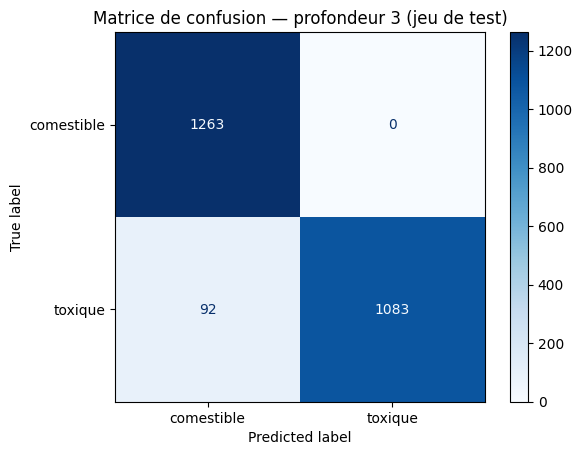

⚠️ Toxiques prédits comestibles (erreur grave) : 92


In [19]:
y_pred = arbre.predict(X_test)                                  # PRÉDICTION sur des données jamais vues
print(f"Accuracy sur le test = {accuracy_score(y_test, y_pred):.4f}")

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
print("Ordre des classes :", labels)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title("Matrice de confusion — profondeur 3 (jeu de test)")
plt.show()

graves = int(((y_test == TOXIQUE) & (y_pred != TOXIQUE)).sum())
print(f"⚠️ Toxiques prédits comestibles (erreur grave) : {graves}")

### 5) Résultat : lire l'arbre
`export_text` affiche l'arbre sous forme de règles : chaque ligne `|--- variable <= 0.5` est une **question**
(après one-hot, « <= 0.5 » signifie « la modalité est absente », « > 0.5 » signifie « présente »).
Les feuilles donnent la classe prédite. Le dessin `plot_tree` montre aussi le Gini et les effectifs de chaque nœud.

|--- odeur__aucune <= 0.50
|   |--- meurtrissures__oui <= 0.50
|   |   |--- class: toxique
|   |--- meurtrissures__oui >  0.50
|   |   |--- couleur_spores__chocolat <= 0.50
|   |   |   |--- class: comestible
|   |   |--- couleur_spores__chocolat >  0.50
|   |   |   |--- class: toxique
|--- odeur__aucune >  0.50
|   |--- couleur_spores__vert <= 0.50
|   |   |--- couleur_chapeau__jaune <= 0.50
|   |   |   |--- class: comestible
|   |   |--- couleur_chapeau__jaune >  0.50
|   |   |   |--- class: toxique
|   |--- couleur_spores__vert >  0.50
|   |   |--- class: toxique



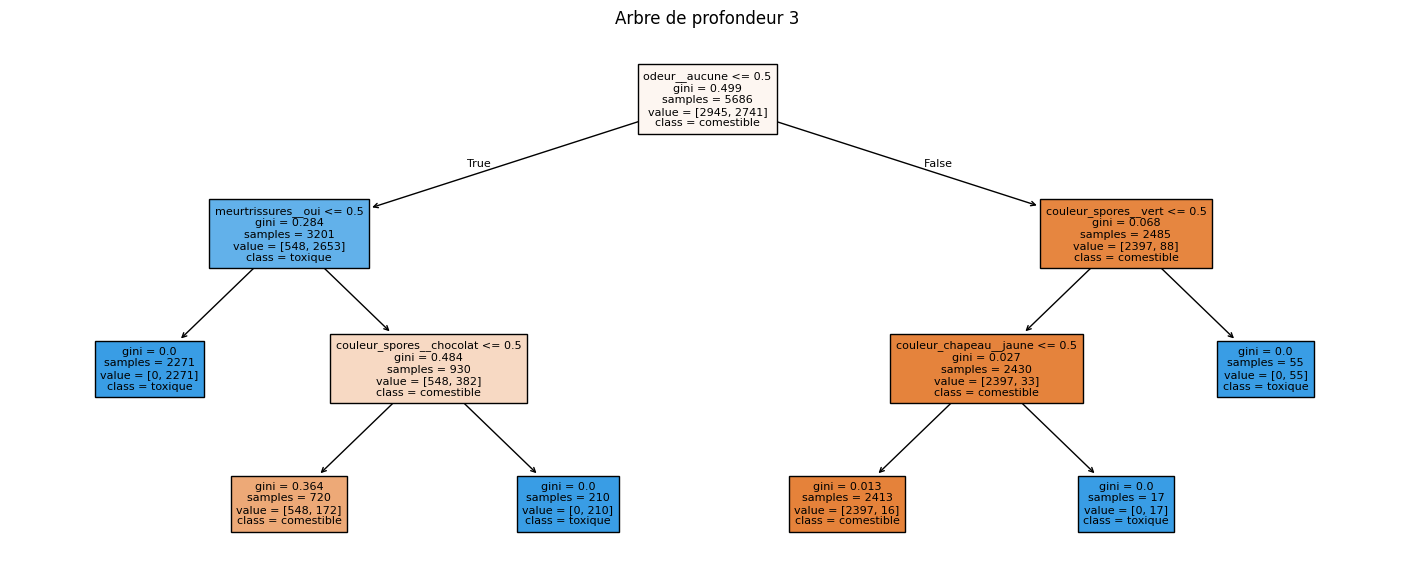

In [20]:
print(export_text(arbre, feature_names=list(X.columns)))

plt.figure(figsize=(18, 7))
plot_tree(arbre, feature_names=X.columns, class_names=[str(c) for c in arbre.classes_],
          filled=True, fontsize=8)
plt.title("Arbre de profondeur 3")
plt.show()

✍️ **Ma réponse B.2** : accuracy test = *(…)* ; matrice de confusion = *(…)* ; première question de l'arbre = *(…)* ;
règles principales = *(…)*.

## B.3 — Profondeur et erreurs graves
**But** : voir l'effet de la profondeur. On entraîne 9 arbres (`max_depth` de 1 à 9) et pour chacun on relève :
* l'**accuracy de test** ;
* le nombre de **toxiques prédits comestibles** (faux négatifs), l'erreur la plus dangereuse.

*Pourquoi ?* Un arbre trop simple se trompe (**sous-apprentissage**), un arbre trop profond peut mémoriser le bruit
(**surapprentissage**). Il faut chercher le bon compromis, et ici surtout **ne manquer aucun champignon toxique**.

,profondeur,accuracy_test,toxiques_predits_comestibles
0,1,0.883511,32
1,2,0.927400,177
2,3,0.962264,92
3,4,0.997129,7
4,5,0.997129,7
5,6,0.997129,7
6,7,0.998769,3
7,8,1.000000,0
8,9,1.000000,0


Profondeur minimale sans aucune erreur grave : 8


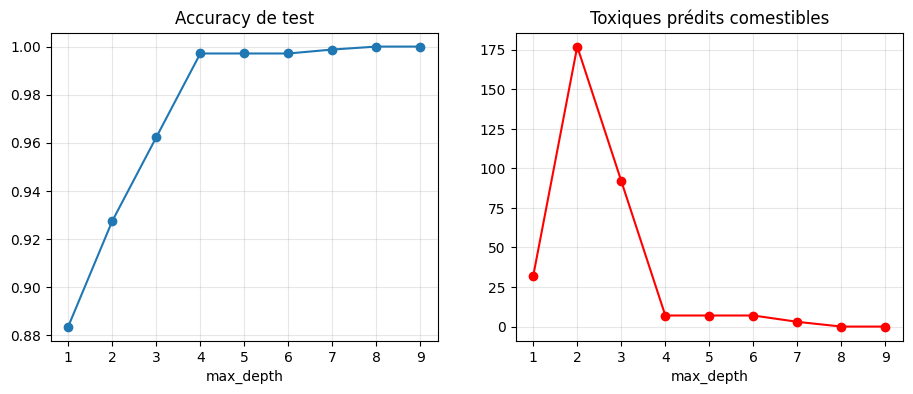

In [21]:
resultats = []
for d in range(1, 10):
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)   # entraînement
    pred = m.predict(X_test)                                                         # prédiction
    acc = accuracy_score(y_test, pred)                                               # test
    graves = int(((y_test == TOXIQUE) & (pred != TOXIQUE)).sum())                    # faux négatifs
    resultats.append((d, acc, graves))

res = pd.DataFrame(resultats, columns=["profondeur", "accuracy_test", "toxiques_predits_comestibles"])
display(res)

sans_erreur = res[res["toxiques_predits_comestibles"] == 0]
print("Profondeur minimale sans aucune erreur grave :",
      int(sans_erreur["profondeur"].min()) if len(sans_erreur) else "aucune entre 1 et 9")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(res["profondeur"], res["accuracy_test"], marker="o")
ax[0].set_title("Accuracy de test")
ax[1].plot(res["profondeur"], res["toxiques_predits_comestibles"], marker="o", color="red")
ax[1].set_title("Toxiques prédits comestibles")
for a in ax:
    a.set_xlabel("max_depth")
    a.grid(alpha=0.3)
plt.show()

✍️ **Ma réponse B.3** :
* Profondeur nécessaire pour ne manquer aucun toxique : *(…)*
* **Pourquoi cette erreur est la seule qui compte vraiment ?** Prédire « comestible » pour un champignon toxique
  peut provoquer une intoxication grave, voire mortelle. L'erreur inverse (prédire « toxique » pour un comestible)
  fait seulement perdre un bon champignon. Les deux erreurs n'ont donc pas le même coût : l'accuracy seule ne suffit pas,
  il faut surveiller le nombre de faux négatifs (le **rappel** de la classe toxique).

## B.4 — Importance des variables
Un arbre peut dire **quelles variables lui ont été les plus utiles** (`feature_importances_`) :
une importance élevée = la variable a beaucoup réduit l'impureté. La somme vaut 1.

Comme `get_dummies` a éclaté chaque variable en plusieurs colonnes, on **regroupe** (somme) par variable d'origine
pour obtenir une lecture claire (ex. toutes les colonnes `odeur__…` ensemble).

Top 10 des colonnes one-hot :
odeur__aucune                 0.625518
meurtrissures__oui            0.162731
odeur__piquante               0.092990
couleur_spores__chocolat      0.066900
couleur_spores__vert          0.037173
couleur_chapeau__jaune        0.011833
surface_chapeau__sillonnee    0.002105
taille_lamelles__etroite      0.000750
forme_chapeau__creux          0.000000
forme_chapeau__cloche         0.000000
dtype: float64


odeur              0.718508
meurtrissures      0.162731
couleur_spores     0.104073
couleur_chapeau    0.011833
surface_chapeau    0.002105
taille_lamelles    0.000750
dtype: float64

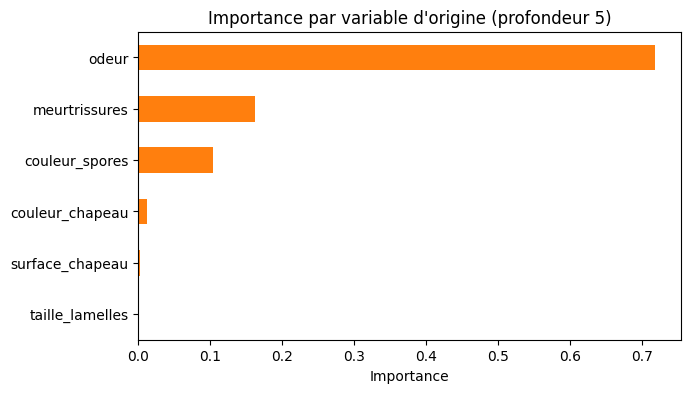

In [22]:
arbre5 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_train, y_train)
imp = pd.Series(arbre5.feature_importances_, index=X.columns)

print("Top 10 des colonnes one-hot :")
print(imp.sort_values(ascending=False).head(10))

# Regroupement par variable d'origine (partie avant '__')
imp_groupe = imp.groupby(lambda c: c.split("__")[0]).sum().sort_values(ascending=False)
imp_groupe = imp_groupe[imp_groupe > 0]
display(imp_groupe)

imp_groupe.plot(kind="barh", figsize=(7, 4), color="tab:orange").invert_yaxis()
plt.title("Importance par variable d'origine (profondeur 5)")
plt.xlabel("Importance")
plt.show()

✍️ **Ma réponse B.4** : la variable la plus utilisée est *(…)* avec une importance de *(…)*, suivie de *(…)*.
Cela confirme / ne confirme pas ce que le tableau croisé de B.1 laissait deviner.

---
# PARTIE C — Avec Orange  · *4 points*
**But** : refaire la même expérience avec un outil **visuel** (sans code) et comparer. Orange propose aussi une
**validation croisée à 10 plis** : les données sont découpées en 10 morceaux ; on entraîne 10 fois en testant à chaque fois
sur un morceau différent. *Pourquoi ?* Le résultat dépend moins d'un seul découpage chanceux ou malchanceux.

Mesures relevées : **CA** (Classification Accuracy = accuracy) et **AUC** (aire sous la courbe ROC : capacité à séparer
toxiques et comestibles, 1 = parfait, 0,5 = hasard).

### Workflow Orange à construire
`File (champignons.csv) → Tree → Tree Viewer` et `File + Tree → Test and Score → Confusion Matrix`

| Étape | Widget | Réglages |
|---|---|---|
| 1 | **File** | ouvrir `champignons.csv`, rôle **target** pour `classe` |
| 2 | **Tree** | profondeur max = **3**, cocher *Induce binary tree*, *Stop when majority reaches* = **100 %** (sinon l'arbre s'arrête dès qu'un nœud est pur à 95 %) |
| 3 | **Tree Viewer** | noter la **première question** et le **nombre de feuilles** |
| 4 | **Test and Score** | *Cross validation*, **10 plis** ; relever **CA** et **AUC** ; puis refaire avec profondeur **5** |

👉 Enregistrer le workflow en **`.ows`** (Fichier → Enregistrer) : c'est un livrable.

### Vérification en Python (validation croisée 10 plis)
Cette cellule reproduit l'esprit du widget *Test and Score*. Les chiffres peuvent différer légèrement d'Orange
(découpage des plis, réglages internes) : **dans le rapport, on rapporte ceux d'Orange** et on les compare à ceux-ci.

In [23]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
y_bin = (y == TOXIQUE).astype(int)          # 1 = toxique, 0 = comestible (nécessaire pour l'AUC)

lignes = []
for d in (3, 5):
    m = DecisionTreeClassifier(max_depth=d, random_state=0)
    ca = cross_val_score(m, X, y_bin, cv=cv, scoring="accuracy").mean()
    auc = cross_val_score(m, X, y_bin, cv=cv, scoring="roc_auc").mean()
    lignes.append((d, round(ca, 4), round(auc, 4)))

display(pd.DataFrame(lignes, columns=["profondeur", "CA (Python)", "AUC (Python)"]))

,profondeur,CA (Python),AUC (Python)
0,3,0.9655,0.9901
1,5,0.9973,0.9999


✍️ **Ma réponse C** *(à remplir avec les résultats d'Orange)* :

| Profondeur | Première question (Tree Viewer) | Nb de feuilles | CA | AUC |
|---|---|---|---|---|
| 3 | | | | |
| 5 | | | | |

Commentaire : *(que se passe-t-il quand on passe de 3 à 5 ? les résultats Orange et Python sont-ils proches ?)*

---
#  Conclusion générale
* **Partie A** : l'arbre choisit à chaque étape la question au **plus grand gain** (Gini / entropie), jusqu'à obtenir des feuilles pures.
* **Partie B** : sur les champignons, quelques questions suffisent (l'odeur domine), mais **la profondeur** détermine si l'on
  évite l'erreur la plus grave (toxique prédit comestible). L'accuracy seule ne suffit pas : on regarde la **matrice de confusion**.
* **Partie C** : Orange confirme les résultats ; la **validation croisée** donne une estimation plus fiable qu'un seul découpage.

✍️ *(Ajouter 3 à 4 lignes personnelles : ce que nous avons compris, difficultés rencontrées, limites du modèle.)*